# Parte 2 — Estimação, comparação e previsão (Níger)

Este notebook resolve as secções 4.2 e 4.3 do guião e continua o notebook 05, de onde vêm a série, a divisão temporal e a identificação:

- resposta: inflação alimentar mensal do Níger, `inflacao_alimentar_log_pct` = 100·Δln(IPC alimentar), em pontos percentuais por mês (aproximadamente %/mês);
- treino: fevereiro de 2000 a dezembro de 2024 (299 meses); teste: janeiro a dezembro de 2025 (12 meses);
- identificação: d = 0, D = 1, s = 12, com SARIMA(0,0,0)(0,1,1)₁₂ como candidato inicial.

**Regra seguida.** Todas as escolhas da secção 4.2 usam só o treino. O modelo final fica fixado no fim da secção 4.2 e os dados de 2025 só entram na secção 4.3, para avaliar previsões já decididas (guião, 4.1.3 e 4.2).

**Leitura principal.**
- Há sazonalidade anual: sem termos sazonais, os resíduos continuam autocorrelacionados, e na validação dentro do treino os modelos sazonais erram menos do que o ARIMA sem componente sazonal e do que as referências simples.
- O modelo final é o SARIMA(0,0,0)(0,1,1)₁₂: tem um só coeficiente, Θ₁ = −0,782, e os resíduos não mostram autocorrelação.
- Em 2025, o SARIMA erra menos do que a referência ingénua sazonal (RMSE 3,632 contra 4,609), mas mais do que o ARIMA sem componente sazonal (3,229) e do que a média do treino (3,273). Em maio e junho de 2025, a inflação alimentar foi a mais baixa desses meses nos 26 anos da série, ao contrário do padrão sazonal que os modelos projetam.

In [1]:
# Bibliotecas: as mesmas das aulas (pandas, numpy, matplotlib e statsmodels)
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.stattools import acf

# Os avisos do statsmodels são silenciados; a convergência de cada estimação é verificada na função ajustar()
warnings.filterwarnings("ignore")

In [2]:
# Raiz do repositório: funciona a partir da pasta notebooks/ ou da raiz
raiz = Path.cwd() if (Path.cwd() / "dados").is_dir() else Path.cwd().parent
pasta_tabelas = raiz / "resultados" / "tabelas" / "06_sarima"
pasta_graficos = raiz / "resultados" / "graficos" / "06_sarima"
pasta_tabelas.mkdir(parents=True, exist_ok=True)
pasta_graficos.mkdir(parents=True, exist_ok=True)

# Cores da paleta das figuras da Parte 1 (scripts/estilo_iscte.py)
AZUL = "#0D28C2"
LARANJA = "#F18D00"
TURQUESA = "#14BFB8"
ROXO = "#8517AC"
CINZA = "#595959"
PRETO = "#171B26"

# Aspeto comum das figuras
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 9


def guardar_csv(tabela, nome, index=False):
    # Valores sem arredondamento, como nas tabelas da Parte 1 (UTF-8 com BOM, para abrir no Excel)
    tabela.to_csv(pasta_tabelas / nome, index=index, encoding="utf-8-sig", date_format="%Y-%m-%d")

In [3]:
# Mesma fonte e mesma divisão treino/teste do notebook 05
painel = pd.read_csv(raiz / "dados" / "processados" / "painel_longo.csv", parse_dates=["data"])
niger = painel[painel["pais_iso3"] == "NER"].set_index("data").sort_index()

# Frequência mensal explícita (MS = primeiro dia de cada mês), para o SARIMAX datar as previsões
y = niger["inflacao_alimentar_log_pct"].asfreq("MS")
amostra = niger["amostra_temporal"].reindex(y.index)
treino = y[amostra == "treino_ate_2024"].asfreq("MS")
teste = y[amostra == "teste_2025"].asfreq("MS")

# Verificações: série completa e divisão igual à do notebook 05
assert y.isna().sum() == 0
assert len(treino) == 299
assert len(teste) == 12
assert treino.index.max() == pd.Timestamp("2024-12-01")
assert teste.index.min() == pd.Timestamp("2025-01-01")
assert teste.index.max() == pd.Timestamp("2025-12-01")

print("Treino:", treino.index.min().date(), "→", treino.index.max().date(), "| n =", len(treino))
print("Teste: ", teste.index.min().date(), "→", teste.index.max().date(), "| n =", len(teste))
print("Média do treino:", round(treino.mean(), 3))
print("Média da série com diff(12) no treino:", round(treino.diff(12).dropna().mean(), 3))
print("Desvio padrão do treino:", round(treino.std(), 3))

# Autocorrelações usadas na identificação (notebook 05), recalculadas com o treino
acf_treino = acf(treino, nlags=36)
acf_dif12 = acf(treino.diff(12).dropna(), nlags=36)
print("ACF do treino: lag 1 =", round(acf_treino[1], 3), "| lags 12, 24 e 36 =", np.round(acf_treino[[12, 24, 36]], 3))
print("ACF da série com diff(12): lags 1 a 3 =", np.round(acf_dif12[1:4], 3), "| lag 12 =", round(acf_dif12[12], 3))

Treino: 2000-02-01 → 2024-12-01 | n = 299
Teste:  2025-01-01 → 2025-12-01 | n = 12
Média do treino: 0.304
Média da série com diff(12) no treino: 0.008
Desvio padrão do treino: 2.459
ACF do treino: lag 1 = 0.249 | lags 12, 24 e 36 = [0.413 0.394 0.375]
ACF da série com diff(12): lags 1 a 3 = [ 0.023  0.024 -0.035] | lag 12 = -0.466


## 4.2 Estimação e comparação

### 4.2.1 Especificações candidatas

As ordens vêm da identificação do notebook 05 (metodologia de Box–Jenkins, aula 3, slide 28). Na série com diff(12), a ACF tem um pico isolado no lag 12 (≈ −0,47) e a PACF decai nos lags 12, 24 e 36: é o padrão de um MA sazonal de ordem 1 (aula 3, slide 7). Nos primeiros lags dessa série, as autocorrelações são próximas de zero. O conjunto é pequeno e cada alternativa testa uma alteração concreta ao candidato inicial:

| Modelo | Especificação | O que testa |
|---|---|---|
| M1 | SARIMA(0,0,0)(0,1,1)₁₂ | Candidato inicial do notebook 05 |
| M2 | SARIMA(1,0,0)(0,1,1)₁₂ | Dependência de curto prazo: na série original, a ACF no lag 1 é 0,25 |
| M3 | SARIMA(0,0,1)(0,1,1)₁₂ | A mesma dependência, na forma MA(1) |
| M4 | SARIMA(0,0,0)(1,1,1)₁₂ | Um AR sazonal (P = 1), além do MA sazonal |
| M5 | SARIMA(0,0,0)(1,0,1)₁₂ com constante | Sem diferença sazonal (D = 0): se o AR sazonal estimado ficar perto de 1, confirma-se D = 1 |
| M6 | ARIMA(1,0,0) com constante | Sem componente sazonal (guião, 4.2.4): AR(1) pelo pico no lag 1 da ACF e da PACF; d = 0 pelos testes ADF e KPSS do notebook 05 |

Os modelos com D = 1 não têm constante: a média da série com diff(12) é 0,008, e uma constante nesse modelo faria a inflação subir o mesmo valor em cada ano, uma tendência que o notebook 05 não encontrou. Os modelos com D = 0 têm constante, porque a média do treino (0,304) não é zero.

Em cada modelo, o Ljung–Box é feito nos lags 12, 24 e 36 (múltiplos do período sazonal), com os graus de liberdade descontados dos coeficientes AR e MA estimados: lag − (p + q + P + Q) (caderno, solução 29). Com diferenciação, as primeiras d + D·s inovações só servem para iniciar as diferenças e ficam fora dos resíduos analisados.

In [4]:
# Especificações candidatas: ordem (p, d, q), ordem sazonal (P, D, Q, s) e constante
# trend="n": sem constante; trend="c": com constante
candidatos = {
    "M1": {"order": (0, 0, 0), "seasonal_order": (0, 1, 1, 12), "trend": "n"},
    "M2": {"order": (1, 0, 0), "seasonal_order": (0, 1, 1, 12), "trend": "n"},
    "M3": {"order": (0, 0, 1), "seasonal_order": (0, 1, 1, 12), "trend": "n"},
    "M4": {"order": (0, 0, 0), "seasonal_order": (1, 1, 1, 12), "trend": "n"},
    "M5": {"order": (0, 0, 0), "seasonal_order": (1, 0, 1, 12), "trend": "c"},
    "M6": {"order": (1, 0, 0), "seasonal_order": (0, 0, 0, 0), "trend": "c"},
}
designacao = {
    "M1": "SARIMA(0,0,0)(0,1,1)12",
    "M2": "SARIMA(1,0,0)(0,1,1)12",
    "M3": "SARIMA(0,0,1)(0,1,1)12",
    "M4": "SARIMA(0,0,0)(1,1,1)12",
    "M5": "SARIMA(0,0,0)(1,0,1)12 + constante",
    "M6": "ARIMA(1,0,0) + constante",
}


def ajustar(serie, especificacao):
    # Estima o modelo por máxima verosimilhança e confirma que a otimização convergiu
    modelo = SARIMAX(serie,
                     order=especificacao["order"],
                     seasonal_order=especificacao["seasonal_order"],
                     trend=especificacao["trend"])
    resultado = modelo.fit(disp=False)
    assert resultado.mle_retvals["converged"], "A estimação não convergiu"
    return resultado


def n_coef_arma(especificacao):
    # Número de coeficientes AR e MA (p + q + P + Q), a descontar nos graus de liberdade do Ljung–Box
    p, d, q = especificacao["order"]
    P, D, Q, s = especificacao["seasonal_order"]
    return p + q + P + Q


def residuos_validos(resultado):
    # Retira as primeiras d + D·s inovações, que dependem da inicialização das diferenças
    return resultado.resid.iloc[resultado.loglikelihood_burn:]


def ljung_box(resultado, especificacao, lags=(12, 24, 36)):
    # H0: autocorrelações dos resíduos nulas até ao lag indicado; graus de liberdade = lag − (p + q + P + Q)
    return acorr_ljungbox(residuos_validos(resultado),
                          lags=list(lags),
                          model_df=n_coef_arma(especificacao),
                          return_df=True)

In [5]:
# Estimação dos seis candidatos, só com o treino
ajustes = {}
linhas = []
coeficientes = []
for nome, especificacao in candidatos.items():
    resultado = ajustar(treino, especificacao)
    ajustes[nome] = resultado
    lb = ljung_box(resultado, especificacao)
    linhas.append({
        "modelo": nome,
        "especificacao": designacao[nome],
        "D": especificacao["seasonal_order"][1],
        "n_parametros": len(resultado.params),
        "obs_verosimilhanca": resultado.nobs - resultado.loglikelihood_burn,
        "log_verosimilhanca": resultado.llf,
        "AIC": resultado.aic,
        "BIC": resultado.bic,
        "LB12_p": lb.loc[12, "lb_pvalue"],
        "LB24_p": lb.loc[24, "lb_pvalue"],
        "LB36_p": lb.loc[36, "lb_pvalue"],
    })
    intervalo = resultado.conf_int(alpha=0.05)
    for termo in resultado.params.index:
        coeficientes.append({
            "modelo": nome,
            "termo": termo,
            "coeficiente": resultado.params[termo],
            "erro_padrao": resultado.bse[termo],
            "valor_p": resultado.pvalues[termo],
            "ic95_inferior": intervalo.loc[termo, 0],
            "ic95_superior": intervalo.loc[termo, 1],
        })

comparacao = pd.DataFrame(linhas)
coeficientes = pd.DataFrame(coeficientes)
guardar_csv(comparacao, "01_candidatos.csv")
guardar_csv(coeficientes, "02_coeficientes.csv")

# n_parametros inclui a variância do erro (sigma2); o AIC e o BIC contam-na
display(comparacao.round(4))
display(coeficientes.round(4))

,modelo,especificacao,D,n_parametros,obs_verosimilhanca,log_verosimilhanca,AIC,BIC,LB12_p,LB24_p,LB36_p
0,M1,"SARIMA(0,0,0)(0,1,1)12",1,2,287,-615.4805,1234.9610,1242.2800,0.7731,0.6839,0.2249
1,M2,"SARIMA(1,0,0)(0,1,1)12",1,3,287,-615.1720,1236.3440,1247.3225,0.7693,0.7327,0.2431
2,M3,"SARIMA(0,0,1)(0,1,1)12",1,3,287,-615.1744,1236.3487,1247.3272,0.7701,0.7313,0.2410
3,M4,"SARIMA(0,0,0)(1,1,1)12",1,3,287,-615.4745,1236.9491,1247.9275,0.6921,0.6297,0.1939
4,M5,"SARIMA(0,0,0)(1,0,1)12 + constante",0,4,299,-637.6009,1283.2019,1298.0036,0.4800,0.6338,0.2272
5,M6,"ARIMA(1,0,0) + constante",0,3,299,-683.3118,1372.6237,1383.7250,0.0000,0.0000,0.0000


,modelo,termo,coeficiente,erro_padrao,valor_p,ic95_inferior,ic95_superior
0,M1,ma.S.L12,-0.7823,0.0473,0.0000,-0.8750,-0.6897
1,M1,sigma2,4.1025,0.2483,0.0000,3.6159,4.5892
2,M2,ar.L1,0.0464,0.0534,0.3850,-0.0583,0.1511
3,M2,ma.S.L12,-0.7837,0.0472,0.0000,-0.8761,-0.6912
4,M2,sigma2,4.0927,0.2505,0.0000,3.6017,4.5837
5,M3,ma.L1,0.0460,0.0548,0.4018,-0.0615,0.1534
6,M3,ma.S.L12,-0.7839,0.0471,0.0000,-0.8762,-0.6915
7,M3,sigma2,4.0927,0.2511,0.0000,3.6005,4.5848
8,M4,ar.S.L12,0.0100,0.0850,0.9067,-0.1567,0.1766
9,M4,ma.S.L12,-0.7884,0.0644,0.0000,-0.9147,-0.6621


**Leitura.**

- M1 a M4 têm a mesma diferenciação e a mesma amostra efetiva (287 meses, depois dos 12 que iniciam a diferença sazonal), por isso os AIC e BIC comparam-se entre si (aula 3, slide 29). O M1 tem o menor AIC (1234,96) e o menor BIC (1242,28).
- Os coeficientes acrescentados em M2, M3 e M4 não são significativos a 5%: φ₁ = 0,046 (p = 0,385), θ₁ = 0,046 (p = 0,402) e Φ₁ = 0,010 (p = 0,907). O Θ₁ quase não muda (−0,782 no M1, −0,788 no M4). A dependência no lag 1 que a ACF da série original mostra desaparece com a diferença sazonal (0,023 no lag 1 da série com diff(12), calculado acima).
- Nos modelos M1 a M5, o Ljung–Box não rejeita a ausência de autocorrelação nos resíduos nos lags 12, 24 e 36 (todos os valores-p ≥ 0,19). No M6, sem termos sazonais, rejeita nos três lags (valores-p < 0,001): a dependência sazonal fica nos resíduos. A sazonalidade anual é sustentada pelos dados e não imposta.
- No M5 (D = 0), o AR sazonal estimado é Φ₁ = 0,961, com IC 95% [0,919; 1,003]. Com Φ₁ = 1, o M5 passaria a ter a diferença sazonal do M1, e a sua constante (0,014; p = 0,492) não é significativa. O intervalo inclui 1, o que reforça D = 1. Um intervalo de Wald não é um teste formal de raiz unitária sazonal (fora dos materiais da UC).
- Os AIC dos modelos com D = 0 (M5 e M6) não se comparam com os de D = 1, porque a verosimilhança usa observações diferentes (299 contra 287). Entre M5 e M6, que partilham essa base, o AIC desce de 1372,6 para 1283,2 com os termos sazonais.

In [6]:
# Verificações das afirmações acima (o notebook para se os dados mudarem e o texto deixar de estar certo)
mesma_diferenciacao = comparacao[comparacao["D"] == 1]
assert mesma_diferenciacao.loc[mesma_diferenciacao["AIC"].idxmin(), "modelo"] == "M1"
assert mesma_diferenciacao.loc[mesma_diferenciacao["BIC"].idxmin(), "modelo"] == "M1"
extras = coeficientes[coeficientes["termo"].isin(["ar.L1", "ma.L1", "ar.S.L12"]) & coeficientes["modelo"].isin(["M2", "M3", "M4"])]
assert (extras["valor_p"] > 0.05).all()
sazonais = comparacao[comparacao["modelo"].isin(["M1", "M2", "M3", "M4", "M5"])]
assert (sazonais[["LB12_p", "LB24_p", "LB36_p"]] > 0.05).all().all()
assert (comparacao.loc[comparacao["modelo"] == "M6", ["LB12_p", "LB24_p", "LB36_p"]] < 0.001).all().all()
print("Menor valor-p do Ljung–Box nos modelos M1 a M5:", round(sazonais[["LB12_p", "LB24_p", "LB36_p"]].min().min(), 4))

Menor valor-p do Ljung–Box nos modelos M1 a M5: 0.1939


### Porque é que o ARIMA sem componente sazonal é o ARIMA(1,0,0)

O ARIMA de comparação deve ser uma especificação razoável e não um modelo fraco de propósito. Estima-se uma grelha pequena de ARIMA não sazonais (p, q ≤ 2, d = 0, com constante) para verificar se outro ARIMA, escolhido pelo AIC, mudaria a conclusão.

In [7]:
# Grelha de ARIMA(p,0,q) com constante, p e q até 2, estimados no treino
grelha = []
for p in range(3):
    for q in range(3):
        especificacao = {"order": (p, 0, q), "seasonal_order": (0, 0, 0, 0), "trend": "c"}
        resultado = ajustar(treino, especificacao)
        lb = ljung_box(resultado, especificacao, lags=(12, 24))
        grelha.append({
            "p": p,
            "q": q,
            "AIC": resultado.aic,
            "BIC": resultado.bic,
            "LB12_p": lb.loc[12, "lb_pvalue"],
            "LB24_p": lb.loc[24, "lb_pvalue"],
        })
grelha = pd.DataFrame(grelha).sort_values("AIC")
guardar_csv(grelha, "03_grelha_arima.csv")
display(grelha.round(4))

# Raízes do ARIMA(2,0,2), o de menor AIC na grelha
arima22 = ajustar(treino, {"order": (2, 0, 2), "seasonal_order": (0, 0, 0, 0), "trend": "c"})
raizes_ar = arima22.arroots
raizes_ma = arima22.maroots
print("Raízes AR:", np.round(raizes_ar, 3), "| módulo:", np.round(np.abs(raizes_ar), 4))
print("Raízes MA:", np.round(raizes_ma, 3), "| módulo:", np.round(np.abs(raizes_ma), 4))
print("Período do ciclo das raízes AR (meses):", np.round(2 * np.pi / np.abs(np.angle(raizes_ar)), 2))
assert (grelha[["LB12_p", "LB24_p"]] < 0.001).all().all()

,p,q,AIC,BIC,LB12_p,LB24_p
8,2,2,1322.2698,1344.4725,0.0,0.0
5,1,2,1371.4350,1389.9372,0.0,0.0
2,0,2,1371.6856,1386.4874,0.0,0.0
3,1,0,1372.6237,1383.7250,0.0,0.0
1,0,1,1374.5295,1385.6308,0.0,0.0
6,2,0,1374.6195,1389.4213,0.0,0.0
4,1,1,1374.6219,1389.4237,0.0,0.0
7,2,1,1376.2375,1394.7398,0.0,0.0
0,0,0,1389.6930,1397.0939,0.0,0.0


Raízes AR: [0.87-0.498j 0.87+0.498j] | módulo: [1.0021 1.0021]
Raízes MA: [0.885-0.471j 0.885+0.471j] | módulo: [1.0026 1.0026]
Período do ciclo das raízes AR (meses): [12.08 12.08]


O menor AIC da grelha é o do ARIMA(2,0,2), mas as suas raízes AR são complexas, com módulo 1,002, quase em cima do círculo unitário, e descrevem um ciclo de 12,1 meses. O modelo imita a sazonalidade anual com uma raiz quase unitária, e as raízes MA (módulo 1,003) quase anulam as AR. É um modelo sazonal disfarçado e numericamente frágil, que não serve como especificação sem componente sazonal. Os nove ARIMA da grelha deixam autocorrelação nos resíduos (valores-p < 0,001 nos lags 12 e 24), por isso a escolha dentro da grelha não muda a conclusão. Fica o M6, ARIMA(1,0,0) com constante. A regra das raízes fora do círculo unitário está no caderno (questão 20); a leitura do período a partir do ângulo das raízes complexas está fora dos materiais da UC.

### Validação com origem móvel dentro do treino

O AIC não compara modelos com diferenciações diferentes, nem mede diretamente a qualidade das previsões (aula 3, slides 29 e 31). Para comparar M1 (D = 1), M5 (D = 0) e M6 (sem sazonalidade) com as referências, repete-se dentro do treino o exercício do teste, com origem móvel (aula 3, slide 30): em dezembro de cada ano de 2014 a 2023, cada modelo é reestimado com os dados até essa data e prevê os 12 meses seguintes. São 10 janelas e 120 previsões por método, de janeiro de 2015 a dezembro de 2024, sem usar 2025.

Referências (aula 3, slides 22 e 31):
- **ingénuo sazonal:** o valor previsto é o observado no mesmo mês do ano anterior (guião, 4.2.3);
- **média:** a média de todo o histórico disponível na origem.

Métricas (aula 3, slide 24), com erro = observado − previsto, na escala da resposta (pontos percentuais por mês): MAE = média de |erro|; RMSE = raiz quadrada da média de erro².

Critério de escolha (aula 3, slide 31): desempenho fora da amostra, estabilidade e simplicidade, com resíduos sem autocorrelação.

In [8]:
# Métricas de previsão (aula 3, slide 24)
def mae(erros):
    return np.mean(np.abs(erros))


def rmse(erros):
    return np.sqrt(np.mean(np.square(erros)))


# Origens em dezembro de 2014 a 2023; horizonte de 12 meses, como no teste
origens = pd.date_range("2014-12-01", "2023-12-01", freq="12MS")
modelos_validacao = ["M1", "M5", "M6"]
registos = []
for origem in origens:
    historico = treino.loc[:origem]
    alvo = treino.loc[origem + pd.DateOffset(months=1):origem + pd.DateOffset(months=12)]
    assert len(alvo) == 12
    previsoes = {}
    for nome in modelos_validacao:
        resultado = ajustar(historico, candidatos[nome])
        previsoes[nome] = resultado.get_forecast(steps=12).predicted_mean.to_numpy()
    # Ingénuo sazonal: os 12 meses do ano da origem repetidos no ano seguinte
    previsoes["Ingénuo sazonal"] = historico.iloc[-12:].to_numpy()
    # Média: média do histórico disponível na origem, igual para os 12 meses
    previsoes["Média"] = np.repeat(historico.mean(), 12)
    for metodo, valores in previsoes.items():
        for h in range(12):
            registos.append({
                "origem": origem.date(),
                "ano_previsto": origem.year + 1,
                "metodo": metodo,
                "data": alvo.index[h].date(),
                "horizonte": h + 1,
                "observado": alvo.iloc[h],
                "previsto": valores[h],
                "erro": alvo.iloc[h] - valores[h],
            })

erros_validacao = pd.DataFrame(registos)
guardar_csv(erros_validacao, "04_validacao_erros.csv")

# MAE e RMSE com as 120 previsões de cada método
ordem_metodos = ["M1", "M5", "M6", "Média", "Ingénuo sazonal"]
metricas_validacao = erros_validacao.groupby("metodo")["erro"].agg(MAE=mae, RMSE=rmse, n="size").reindex(ordem_metodos)
# Diferença do M1 face a cada método, em %: negativa quando o M1 erra menos
metricas_validacao["RMSE_M1_face_pct"] = 100 * (metricas_validacao.loc["M1", "RMSE"] / metricas_validacao["RMSE"] - 1)
metricas_validacao["MAE_M1_face_pct"] = 100 * (metricas_validacao.loc["M1", "MAE"] / metricas_validacao["MAE"] - 1)
guardar_csv(metricas_validacao, "05_validacao_metricas.csv", index=True)
display(metricas_validacao.round(3))

# RMSE em cada janela e número de janelas em que o M1 erra menos
rmse_janela = erros_validacao.groupby(["ano_previsto", "metodo"])["erro"].agg(rmse).unstack()[ordem_metodos]
guardar_csv(rmse_janela, "06_validacao_rmse_por_janela.csv", index=True)
display(rmse_janela.round(3))
for outro in ["M5", "M6", "Média", "Ingénuo sazonal"]:
    vitorias = int((rmse_janela["M1"] < rmse_janela[outro]).sum())
    print(f"M1 com RMSE menor do que {outro}: {vitorias} de {len(rmse_janela)} janelas")

,MAE,RMSE,n,RMSE_M1_face_pct,MAE_M1_face_pct
metodo,,,,,
M1,1.541,2.036,120,0.000,0.000
M5,1.494,2.013,120,1.141,3.184
M6,1.694,2.233,120,-8.855,-9.029
Média,1.704,2.247,120,-9.428,-9.524
Ingénuo sazonal,1.859,2.588,120,-21.350,-17.109


metodo,M1,M5,M6,Média,Ingénuo sazonal
ano_previsto,,,,,
2015,2.513,2.407,2.513,2.568,2.194
2016,2.030,2.103,2.577,2.582,3.258
2017,2.837,2.722,2.420,2.460,3.668
2018,1.601,1.616,1.837,1.841,3.362
2019,1.279,1.090,0.984,1.015,1.605
2020,1.646,1.590,1.717,1.716,2.122
2021,1.388,1.356,1.700,1.698,1.121
2022,1.234,1.128,1.337,1.354,1.163
2023,2.213,2.215,2.459,2.462,2.465


M1 com RMSE menor do que M5: 4 de 10 janelas
M1 com RMSE menor do que M6: 8 de 10 janelas
M1 com RMSE menor do que Média: 8 de 10 janelas
M1 com RMSE menor do que Ingénuo sazonal: 7 de 10 janelas


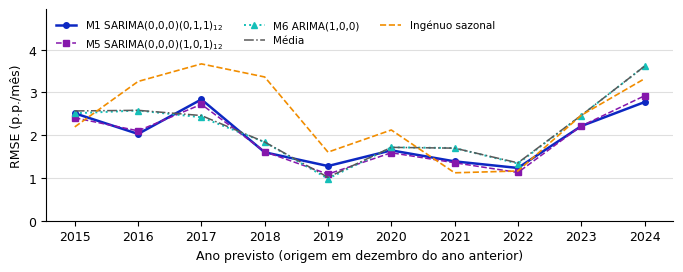

In [9]:
# Figura 6.1: RMSE de cada janela de validação, por método (só treino)
estilos = {
    "M1": {"color": AZUL, "linestyle": "-", "marker": "o", "linewidth": 1.8},
    "M5": {"color": ROXO, "linestyle": "--", "marker": "s", "linewidth": 1.1},
    "M6": {"color": TURQUESA, "linestyle": ":", "marker": "^", "linewidth": 1.4},
    "Média": {"color": CINZA, "linestyle": "-.", "marker": "", "linewidth": 1.1},
    "Ingénuo sazonal": {"color": LARANJA, "linestyle": "--", "marker": "", "linewidth": 1.2},
}
rotulos = {
    "M1": "M1 SARIMA(0,0,0)(0,1,1)$_{12}$",
    "M5": "M5 SARIMA(0,0,0)(1,0,1)$_{12}$",
    "M6": "M6 ARIMA(1,0,0)",
    "Média": "Média",
    "Ingénuo sazonal": "Ingénuo sazonal",
}
fig, ax = plt.subplots(figsize=(6.9, 2.8))
for metodo in ordem_metodos:
    ax.plot(rmse_janela.index, rmse_janela[metodo], label=rotulos[metodo], markersize=4, **estilos[metodo])
ax.set_xticks(rmse_janela.index)
ax.set_xlabel("Ano previsto (origem em dezembro do ano anterior)")
ax.set_ylabel("RMSE (p.p./mês)")
ax.grid(axis="y", alpha=0.4)
ax.legend(ncol=3, fontsize=7.5, frameon=False, loc="upper left")
ax.set_ylim(0, rmse_janela.max().max() * 1.35)
fig.tight_layout()
fig.savefig(pasta_graficos / "01_validacao_rmse_por_janela.png", dpi=300)
# Sem data de criação no PDF, para o ficheiro não mudar quando o notebook é reexecutado
fig.savefig(pasta_graficos / "01_validacao_rmse_por_janela.pdf", metadata={"CreationDate": None})
plt.show()

**Figura 6.1.** RMSE das previsões a 1–12 meses em cada janela da validação com origem móvel (treino, 2015–2024). Cada ponto resume os 12 meses do ano indicado.

**Leitura da validação.**
- Os dois modelos sazonais têm os menores erros: RMSE 2,013 (M5) e 2,036 (M1), contra 2,233 do ARIMA sem componente sazonal (M6), 2,247 da média e 2,588 do ingénuo sazonal. O MAE ordena os métodos da mesma forma. O M1 erra menos do que o M6 em 8 das 10 janelas (em 2015, por menos de 0,001), do que a média em 8 e do que o ingénuo sazonal em 7.
- O ingénuo sazonal é a pior referência no conjunto: repete o ano anterior, incluindo os seus extremos. O SARIMA pondera vários anos do mesmo mês, e o seu RMSE é 21,3% menor.
- M1 e M5 são quase o mesmo modelo (Φ₁ = 0,961 no M5) e fazem previsões muito parecidas. O M5 erra um pouco menos: o RMSE do M1 é 1,1% maior e o MAE 3,2% maior, e o M5 tem RMSE menor em 6 das 10 janelas.

### Modelo final: M1, SARIMA(0,0,0)(0,1,1)₁₂

Segue os critérios da aula 3 (slides 28 a 31):
1. Entre os modelos com a mesma diferenciação, tem o menor AIC e o menor BIC, e os termos extra dos outros não são significativos.
2. Os resíduos não mostram autocorrelação (secção 4.2.2).
3. Na validação, erra menos do que o ARIMA sem componente sazonal, a média e o ingénuo sazonal, e só um pouco mais do que o M5.
4. É o mais simples: um coeficiente, contra três no M5 (Φ₁, Θ₁ e constante). A diferença sazonal é coerente com a identificação do notebook 05, e o Φ₁ ≈ 1 do M5 confirma-a. A pequena vantagem do M5 na validação não compensa os dois coeficientes a mais.

O M5 continua na comparação da secção 4.3, para mostrar o efeito da escolha entre D = 0 e D = 1. A escolha ficou fixada aqui, antes de usar os dados de 2025.

In [10]:
# Verificações das afirmações da validação
# Em cada métrica, os dois modelos sazonais erram menos do que o ARIMA e as duas referências
for metrica in ["MAE", "RMSE"]:
    assert metricas_validacao.loc[["M1", "M5"], metrica].max() < metricas_validacao.loc[["M6", "Média", "Ingénuo sazonal"], metrica].min()
assert metricas_validacao.loc["M5", "RMSE"] < metricas_validacao.loc["M1", "RMSE"]
assert metricas_validacao.loc["Ingénuo sazonal", "RMSE"] == metricas_validacao["RMSE"].max()
print("RMSE do M1 face a cada método (%):", metricas_validacao["RMSE_M1_face_pct"].round(1).to_dict())
print("MAE do M1 face a cada método (%):", metricas_validacao["MAE_M1_face_pct"].round(1).to_dict())
print("Diferença de RMSE entre M6 e M1 em 2015:", round(rmse_janela.loc[2015, "M6"] - rmse_janela.loc[2015, "M1"], 4))

RMSE do M1 face a cada método (%): {'M1': 0.0, 'M5': 1.1, 'M6': -8.9, 'Média': -9.4, 'Ingénuo sazonal': -21.3}
MAE do M1 face a cada método (%): {'M1': 0.0, 'M5': 3.2, 'M6': -9.0, 'Média': -9.5, 'Ingénuo sazonal': -17.1}
Diferença de RMSE entre M6 e M1 em 2015: 0.0006


### 4.2.2 Diagnóstico dos resíduos do modelo final

O modelo final é $(1 - B^{12})\,y_t = (1 + \Theta_1 B^{12})\,\varepsilon_t$, ou seja, $y_t = y_{t-12} + \varepsilon_t + \Theta_1\,\varepsilon_{t-12}$, com a convenção de sinal do MA da UC (1 + ΘB). Analisam-se os resíduos a partir de fevereiro de 2001 (287 meses), depois dos 12 que iniciam a diferença sazonal.

In [11]:
# Resumo do modelo final, estimado no treino
final = ajustes["M1"]
print(final.summary())

                                   SARIMAX Results                                    
Dep. Variable:     inflacao_alimentar_log_pct   No. Observations:                  299
Model:                 SARIMAX(0, 1, [1], 12)   Log Likelihood                -615.481
Date:                        Sat, 21 Nov 2026   AIC                           1234.961
Time:                                00:06:28   BIC                           1242.280
Sample:                            02-01-2000   HQIC                          1237.894
                                 - 12-01-2024                                         
Covariance Type:                          opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.S.L12      -0.7823      0.047    -16.554      0.000      -0.875      -0.690
sigma2         4.1025      0.248     16.523      0.000       3.616 

In [12]:
# Ljung–Box nos lags 12, 24 e 36, com graus de liberdade = lag − 1 (um coeficiente MA sazonal)
lb_final = ljung_box(final, candidatos["M1"])
lb_final["graus_liberdade"] = lb_final.index - n_coef_arma(candidatos["M1"])
lb_final.index.name = "lag"
guardar_csv(lb_final, "07_ljung_box_M1.csv", index=True)
display(lb_final.round(4))

# Normalidade (Jarque–Bera) e variância constante (teste H do statsmodels: último terço contra primeiro terço)
jarque_bera = final.test_normality("jarquebera")[0]
heteroscedasticidade = final.test_heteroskedasticity("breakvar")[0]
print("Jarque–Bera:", round(jarque_bera[0], 2), "| valor-p:", jarque_bera[1], "| assimetria:", round(jarque_bera[2], 2), "| curtose:", round(jarque_bera[3], 2))
print("H:", round(heteroscedasticidade[0], 3), "| valor-p:", round(heteroscedasticidade[1], 3))

# Resíduos: média e desvio padrão em cada ano
residuos = residuos_validos(final)
print("Resíduos analisados:", residuos.index.min().date(), "→", residuos.index.max().date(), "| n =", len(residuos))
print("Média dos resíduos:", round(residuos.mean(), 3))
print("RMSE a um passo no treino:", round(rmse(residuos), 3))
acf_residuos = acf(residuos, nlags=36)
banda = 1.96 / np.sqrt(len(residuos))
print("ACF dos resíduos nos lags 12, 24 e 36:", np.round(acf_residuos[[12, 24, 36]], 3), "| banda aproximada ±", round(banda, 3))
fora_da_banda = [lag for lag in range(1, 37) if abs(acf_residuos[lag]) > banda]
print("Lags 1 a 36 fora da banda:", {lag: round(acf_residuos[lag], 3) for lag in fora_da_banda})
dp_ano = residuos.groupby(residuos.index.year).std()
print("Desvio padrão anual dos resíduos: mínimo", round(dp_ano.min(), 2), "em", dp_ano.idxmin(), "| máximo", round(dp_ano.max(), 2), "em", dp_ano.idxmax())
print("Anos com desvio padrão acima de 2,5:", list(dp_ano[dp_ano > 2.5].round(2).items()))
assert (lb_final["lb_pvalue"] > 0.05).all()

,lb_stat,lb_pvalue,graus_liberdade
lag,,,
12,7.3145,0.7731,11
24,19.2966,0.6839,23
36,40.9747,0.2249,35


Jarque–Bera: 60.74 | valor-p: 6.463170147184164e-14 | assimetria: 0.64 | curtose: 4.85
H: 0.829 | valor-p: 0.359
Resíduos analisados: 2001-02-01 → 2024-12-01 | n = 287
Média dos resíduos: 0.019
RMSE a um passo no treino: 2.062
ACF dos resíduos nos lags 12, 24 e 36: [-0.014 -0.003  0.03 ] | banda aproximada ± 0.116
Lags 1 a 36 fora da banda: {25: np.float64(-0.134), 35: np.float64(0.159)}
Desvio padrão anual dos resíduos: mínimo 1.19 em 2014 | máximo 3.4 em 2005
Anos com desvio padrão acima de 2,5: [(2005, 3.4), (2008, 2.65), (2010, 2.75), (2015, 2.63), (2017, 2.92), (2024, 2.89)]


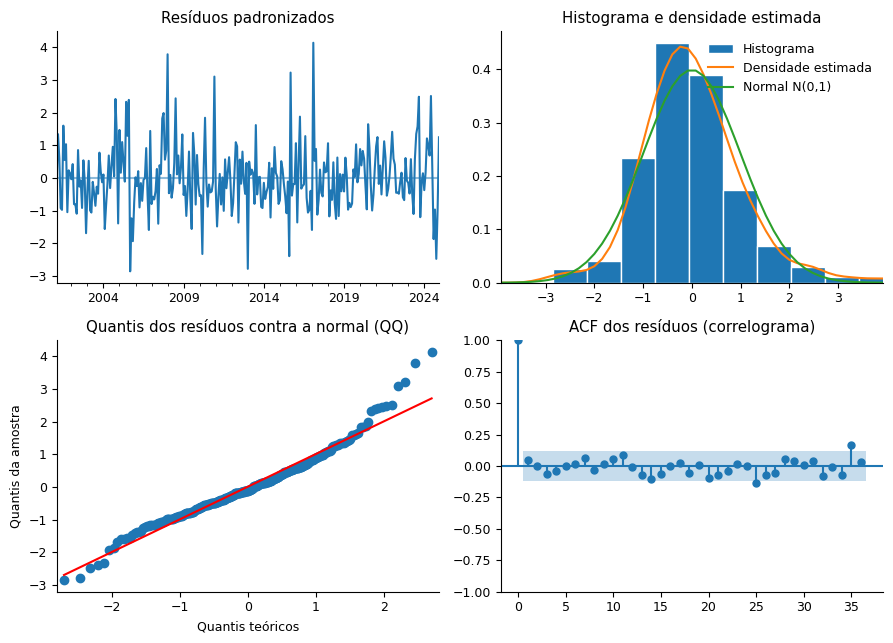

In [13]:
# Figura 6.2: resíduos padronizados, histograma, QQ normal e correlograma até ao lag 36
fig = final.plot_diagnostics(figsize=(9, 6.5), lags=36)
eixos = fig.axes
eixos[0].set_title("Resíduos padronizados")
eixos[0].set_xlabel("")
eixos[1].set_title("Histograma e densidade estimada")
pegas, nomes = eixos[1].get_legend_handles_labels()
traducao = {"Hist": "Histograma", "KDE": "Densidade estimada", "N(0,1)": "Normal N(0,1)"}
eixos[1].legend(pegas, [traducao.get(nome, nome) for nome in nomes], frameon=False)
eixos[2].set_title("Quantis dos resíduos contra a normal (QQ)")
eixos[2].set_xlabel("Quantis teóricos")
eixos[2].set_ylabel("Quantis da amostra")
eixos[3].set_title("ACF dos resíduos (correlograma)")
fig.tight_layout()
fig.savefig(pasta_graficos / "02_diagnostico_residuos_M1.png", dpi=300)
plt.show()

**Figura 6.2.** Diagnóstico dos resíduos do M1 no treino (statsmodels, `plot_diagnostics`): resíduos padronizados ao longo do tempo, histograma com densidade, quantis contra a normal e ACF até ao lag 36.

**Leitura.**
- **Coeficiente.** Θ₁ = −0,782 (erro padrão 0,047; IC 95% [−0,875; −0,690]). Como |Θ₁| < 1, o MA sazonal é invertível (caderno, questão 20). A variância do erro estimada é σ² = 4,10.
- **Autocorrelação.** O Ljung–Box não rejeita a ausência de autocorrelação nos lags 12, 24 e 36 (valores-p 0,773, 0,684 e 0,225, com 11, 23 e 35 graus de liberdade). Nos lags 12, 24 e 36, a ACF dos resíduos é −0,014, −0,003 e 0,030, dentro da banda aproximada de ±0,116; só os lags 25 (−0,13) e 35 (0,16) saem da banda, 2 em 36, perto do que se espera por acaso a 5%. Não rejeitar não prova independência (caderno, solução 29), mas não fica dependência linear relevante por explicar.
- **Média.** A média dos resíduos é 0,019, praticamente zero.
- **Normalidade.** O Jarque–Bera rejeita a normalidade (valor-p < 0,001): assimetria 0,64 e curtose 4,85, acima de 3. Há mais meses extremos do que a normal prevê. O guião não pede que a normalidade decida a validade do modelo, mas os intervalos de previsão de 95% assumem erros normais e podem subestimar a probabilidade de desvios grandes.
- **Variância.** O teste H (último terço contra primeiro terço) não rejeita variância igual (H = 0,829; valor-p 0,359), mas o desvio padrão anual dos resíduos vai de 1,19 em 2014 a 3,40 em 2005, e passa de 2,5 em 2005, 2008, 2010, 2015, 2017 e 2024. A variância muda por períodos, e o teste, que só compara o primeiro e o último terço da amostra, não o capta. Com variância constante no modelo, os intervalos de previsão tendem a ser largos demais nos anos calmos e estreitos demais nos anos voláteis.

Os resíduos comportam-se aproximadamente como ruído branco (aula 3, slide 28), e o M1 segue para a previsão.

## 4.3 Previsão e avaliação

Todos os métodos preveem janeiro a dezembro de 2025 a partir do fim do treino (dezembro de 2024), com horizontes de 1 a 12 meses, e todos os modelos foram estimados só com o treino:

- **M1**, o modelo final, com intervalo de previsão de 95%;
- **M5** (D = 0) e **M6** (ARIMA sem componente sazonal), para responder às questões do guião;
- **ingénuo sazonal:** cada mês de 2025 recebe o valor do mesmo mês de 2024;
- **média do treino:** 0,304 em todos os meses.

**Escala.** A resposta não foi transformada para a modelação: já é a inflação definida na Parte 1, 100·Δln(IPC alimentar). A diferença sazonal faz parte do modelo, e o SARIMAX devolve as previsões na escala da resposta, por isso não há transformação inversa a aplicar. MAE e RMSE estão em pontos percentuais por mês.

In [14]:
# Previsões a 12 meses a partir de dezembro de 2024
previsao_final = final.get_forecast(steps=12)
intervalo_95 = previsao_final.conf_int(alpha=0.05)
assert previsao_final.predicted_mean.index.equals(teste.index)

previsoes_teste = pd.DataFrame({
    "observado": teste,
    "M1": previsao_final.predicted_mean,
    "M1_ic95_inferior": intervalo_95.iloc[:, 0],
    "M1_ic95_superior": intervalo_95.iloc[:, 1],
    "M5": ajustes["M5"].get_forecast(steps=12).predicted_mean,
    "M6": ajustes["M6"].get_forecast(steps=12).predicted_mean,
    "Ingénuo sazonal": treino.iloc[-12:].to_numpy(),
    "Média": treino.mean(),
}, index=teste.index)
guardar_csv(previsoes_teste, "08_previsoes_2025.csv", index=True)
display(previsoes_teste.round(2))

# MAE, RMSE e erro médio (observado − previsto) no teste
metricas_teste = pd.DataFrame({
    metodo: {
        "MAE": mae(teste - previsoes_teste[metodo]),
        "RMSE": rmse(teste - previsoes_teste[metodo]),
        "erro_medio": np.mean(teste - previsoes_teste[metodo]),
    }
    for metodo in ordem_metodos
}).T
metricas_teste.index.name = "metodo"
# Diferença do M1 face a cada método, em %: negativa quando o M1 erra menos
metricas_teste["RMSE_M1_face_pct"] = 100 * (metricas_teste.loc["M1", "RMSE"] / metricas_teste["RMSE"] - 1)
metricas_teste["MAE_M1_face_pct"] = 100 * (metricas_teste.loc["M1", "MAE"] / metricas_teste["MAE"] - 1)
guardar_csv(metricas_teste, "09_metricas_teste.csv", index=True)
display(metricas_teste.round(3))

# Meses de 2025 dentro do intervalo de 95% do M1
dentro = (teste >= previsoes_teste["M1_ic95_inferior"]) & (teste <= previsoes_teste["M1_ic95_superior"])
print("Meses dentro do intervalo de 95% do M1:", int(dentro.sum()), "de 12")
print("Meses fora:", [data.strftime("%Y-%m") for data in teste.index[~dentro]])
largura = previsoes_teste["M1_ic95_superior"] - previsoes_teste["M1_ic95_inferior"]
print("Semi-amplitude do intervalo nos 12 meses: de", round(largura.min() / 2, 2), "a", round(largura.max() / 2, 2))
intervalo_24 = final.get_forecast(steps=24).conf_int(alpha=0.05)
print("Semi-amplitude a 13 meses (só para comparação):", round((intervalo_24.iloc[12, 1] - intervalo_24.iloc[12, 0]) / 2, 2))

# A previsão do M1 é 0,218 × (valor do mesmo mês de 2024) + 0,782 × (previsão a um passo desse mês de 2024)
theta = final.params["ma.S.L12"]
previsao_formula = (1 + theta) * treino.iloc[-12:].to_numpy() - theta * final.fittedvalues.iloc[-12:].to_numpy()
assert np.allclose(previsao_formula, previsoes_teste["M1"].to_numpy(), atol=1e-3)
print("Pesos da previsão: 1 + Θ1 =", round(1 + theta, 3), "no valor de 2024 e −Θ1 =", round(-theta, 3), "na previsão a um passo de 2024")
print("Junho de 2024: observado", round(treino.loc["2024-06-01"], 2), "| previsto a um passo", round(final.fittedvalues.loc["2024-06-01"], 2))

,observado,M1,M1_ic95_inferior,M1_ic95_superior,M5,M6,Ingénuo sazonal,Média
data,,,,,,,,
2025-01-01,3.79,-0.27,-4.24,3.70,-0.13,0.82,-0.86,0.3
2025-02-01,0.62,-0.04,-4.01,3.93,0.08,0.43,0.23,0.3
2025-03-01,1.56,0.40,-3.57,4.37,0.48,0.34,2.32,0.3
2025-04-01,2.16,1.88,-2.09,5.85,1.67,0.31,3.45,0.3
2025-05-01,-6.17,1.53,-2.44,5.50,1.30,0.31,2.62,0.3
2025-06-01,-2.51,3.30,-0.67,7.27,2.90,0.31,7.27,0.3
2025-07-01,0.17,1.93,-2.04,5.90,1.77,0.31,2.51,0.3
2025-08-01,-3.54,0.52,-3.45,4.49,0.49,0.31,-2.44,0.3
2025-09-01,-4.54,-0.29,-4.26,3.68,-0.18,0.31,-1.82,0.3


,MAE,RMSE,erro_medio,RMSE_M1_face_pct,MAE_M1_face_pct
metodo,,,,,
M1,2.751,3.632,-1.698,0.000,0.000
M5,2.709,3.533,-1.704,2.795,1.559
M6,2.686,3.229,-1.651,12.449,2.409
Média,2.742,3.273,-1.592,10.965,0.327
Ingénuo sazonal,3.526,4.609,-1.772,-21.201,-21.986


Meses dentro do intervalo de 95% do M1: 7 de 12
Meses fora: ['2025-01', '2025-05', '2025-06', '2025-08', '2025-09']
Semi-amplitude do intervalo nos 12 meses: de 3.97 a 3.97
Semi-amplitude a 13 meses (só para comparação): 4.06
Pesos da previsão: 1 + Θ1 = 0.218 no valor de 2024 e −Θ1 = 0.782 na previsão a um passo de 2024
Junho de 2024: observado 7.27 | previsto a um passo 2.19


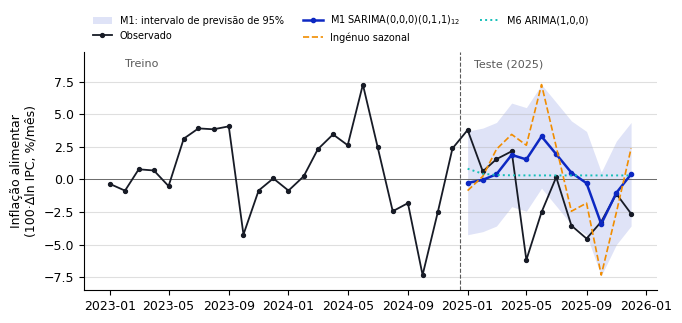

In [15]:
# Figura 6.3: valores observados, previsões e intervalo de previsão de 95% do M1
inicio = pd.Timestamp("2023-01-01")
observado = y.loc[inicio:]
fig, ax = plt.subplots(figsize=(6.9, 3.3))
ax.axhline(0, color=CINZA, linewidth=0.6)
ax.axvline(pd.Timestamp("2024-12-16"), color=CINZA, linewidth=0.8, linestyle="--")
ax.fill_between(previsoes_teste.index,
                previsoes_teste["M1_ic95_inferior"],
                previsoes_teste["M1_ic95_superior"],
                color=AZUL,
                alpha=0.13,
                linewidth=0,
                label="M1: intervalo de previsão de 95%")
ax.plot(observado.index, observado, color=PRETO, linewidth=1.3, marker="o", markersize=2.8, label="Observado")
ax.plot(previsoes_teste.index, previsoes_teste["M1"], color=AZUL, linewidth=1.8, marker="o", markersize=3, label="M1 SARIMA(0,0,0)(0,1,1)$_{12}$")
ax.plot(previsoes_teste.index, previsoes_teste["Ingénuo sazonal"], color=LARANJA, linewidth=1.2, linestyle="--", label="Ingénuo sazonal")
ax.plot(previsoes_teste.index, previsoes_teste["M6"], color=TURQUESA, linewidth=1.4, linestyle=":", label="M6 ARIMA(1,0,0)")
ax.text(pd.Timestamp("2023-02-01"), 8.6, "Treino", color=CINZA, fontsize=8)
ax.text(pd.Timestamp("2025-01-15"), 8.6, "Teste (2025)", color=CINZA, fontsize=8)
ax.set_ylabel("Inflação alimentar\n(100·Δln IPC, %/mês)")
ax.set_ylim(-8.5, 9.8)
ax.grid(axis="y", alpha=0.4)
ax.legend(ncol=3, fontsize=7, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
fig.savefig(pasta_graficos / "03_previsao_2025.png", dpi=300)
# Sem data de criação no PDF, para o ficheiro não mudar quando o notebook é reexecutado
fig.savefig(pasta_graficos / "03_previsao_2025.pdf", metadata={"CreationDate": None})
plt.show()

**Figura 6.3.** Inflação alimentar mensal do Níger, 2023–2025: valores observados, previsões para 2025 feitas em dezembro de 2024 e intervalo de previsão de 95% do M1.

**Leitura das previsões.**
- **Face à referência ingénua sazonal, o SARIMA melhora:** RMSE 3,632 contra 4,609 e MAE 2,751 contra 3,526, ou seja, 21,2% e 22,0% menos. O ingénuo sazonal repete 2024, um ano com extremos (+7,27 em junho e −7,33 em outubro); o M1 pondera os anos anteriores e prevê 3,30 para junho.
- **Face ao ARIMA sem componente sazonal e à média, o SARIMA não melhora em 2025:** o M6 tem RMSE 3,229 e MAE 2,686; a média do treino tem RMSE 3,273 e MAE 2,742. O RMSE do M1 é 12,4% maior do que o do M6 e 11,0% maior do que o da média; no MAE, o M1 fica praticamente igual à média (2,751 contra 2,742). O M5 (D = 0) fica perto do M1 (RMSE 3,533), por isso a escolha entre D = 0 e D = 1 não muda a conclusão.
- **Todos os métodos sobrestimaram 2025.** O erro médio do M1 é −1,698: em média, a inflação observada ficou 1,7 pontos por mês abaixo da prevista. Só 7 dos 12 meses caem dentro do intervalo de 95% do M1; ficam fora janeiro (acima) e maio, junho, agosto e setembro (abaixo).
- **O intervalo tem a mesma largura nos 12 meses (±3,97).** Na equação $y_{T+h} = y_{T+h-12} + \varepsilon_{T+h} + \Theta_1\,\varepsilon_{T+h-12}$, para h ≤ 12 o valor do mesmo mês de 2024 e o respetivo choque (estimado pelo resíduo) já são conhecidos; só o choque do próprio mês fica por conhecer, com variância σ². A partir do 13.º mês, o intervalo alargaria (±4,06).
- **Como o M1 chega a cada previsão.** Como $\hat\varepsilon = y - \hat y$ (erro da previsão a um passo), $\hat y_{T+h} = (1+\Theta_1)\,y_{T+h-12} - \Theta_1\,\hat y_{T+h-12}$: com Θ₁ = −0,782, cada mês de 2025 recebe 0,218 × o valor desse mês em 2024 + 0,782 × a previsão a um passo que o modelo fazia para esse mês de 2024 (conferido acima com a saída do statsmodels).

Em 2025, o M6 e a média ficaram à frente dos dois SARIMA, ao contrário do que aconteceu na validação de 2015–2024. A tabela seguinte mostra porquê.

In [16]:
# Erros mensais do M1 e posição de cada mês de 2025 na história do mesmo mês
anos_por_mes = y.groupby(y.index.month).size()
posicao_2025 = [int((y[y.index.month == mes] <= teste[teste.index.month == mes].iloc[0]).sum()) for mes in range(1, 13)]
minimo_treino = treino.groupby(treino.index.month).min()
media_treino_mes = treino.groupby(treino.index.month).mean()
erros_mensais = pd.DataFrame({
    "observado": teste.to_numpy(),
    "previsto_M1": previsoes_teste["M1"].to_numpy(),
    "erro_M1": (teste - previsoes_teste["M1"]).to_numpy(),
    "dentro_ic95": dentro.to_numpy(),
    "media_treino_mes": media_treino_mes.to_numpy(),
    "minimo_treino_mes": minimo_treino.to_numpy(),
    "posicao_2025_1_e_o_mais_baixo": posicao_2025,
    "anos_com_o_mes": anos_por_mes.to_numpy(),
}, index=pd.Index(teste.index.strftime("%Y-%m"), name="mes"))
guardar_csv(erros_mensais, "10_erros_mensais_M1.csv", index=True)
display(erros_mensais.round(2))
print("Maiores erros absolutos do M1:")
print(erros_mensais["erro_M1"].abs().sort_values(ascending=False).head(5).round(2))
print("Três valores mais altos do treino:", treino.nlargest(3).round(2).to_dict())

# Variação acumulada do IPC alimentar em 2025: soma das 12 variações logarítmicas
soma_observada = teste.sum()
soma_prevista = previsoes_teste["M1"].sum()
print("Soma de 2025 (pontos logarítmicos): observada", round(soma_observada, 2), "| prevista pelo M1", round(soma_prevista, 2))
print("Variação do IPC alimentar de dez/2024 a dez/2025 (%): observada", round(100 * (np.exp(soma_observada / 100) - 1), 1), "| prevista pelo M1", round(100 * (np.exp(soma_prevista / 100) - 1), 1))

# Informação disponível no painel: défice hídrico de 3 meses (positivo = mais seco) no fim de 2024
defice = niger["defice_hidrico_3m_z"].asfreq("MS")
defice_treino = defice.loc[treino.index]
for mes in [8, 9, 10]:
    valores_mes = defice_treino[defice_treino.index.month == mes]
    valor_2024 = valores_mes[valores_mes.index.year == 2024].iloc[0]
    posicao = int((valores_mes <= valor_2024).sum())
    print(f"Défice hídrico em {mes:02d}/2024: {valor_2024:.2f} desvios padrão | posição {posicao} de {len(valores_mes)} anos (1 = mais húmido)")
assert posicao_2025[4] == 1
assert posicao_2025[5] == 1

,observado,previsto_M1,erro_M1,dentro_ic95,media_treino_mes,minimo_treino_mes,posicao_2025_1_e_o_mais_baixo,anos_com_o_mes
mes,,,,,,,,
2025-01,3.79,-0.27,4.06,False,-0.47,-5.57,24,25
2025-02,0.62,-0.04,0.65,True,-0.74,-4.62,21,26
2025-03,1.56,0.40,1.16,True,-0.24,-4.62,23,26
2025-04,2.16,1.88,0.28,True,1.36,-0.45,19,26
2025-05,-6.17,1.53,-7.71,False,2.14,-0.51,1,26
2025-06,-2.51,3.30,-5.81,False,4.03,0.49,1,26
2025-07,0.17,1.93,-1.76,True,0.80,-2.11,11,26
2025-08,-3.54,0.52,-4.05,False,0.06,-4.65,2,26
2025-09,-4.54,-0.29,-4.25,False,-0.85,-7.59,2,26


Maiores erros absolutos do M1:
mes
2025-05    7.71
2025-06    5.81
2025-09    4.25
2025-01    4.06
2025-08    4.05
Name: erro_M1, dtype: float64
Três valores mais altos do treino: {Timestamp('2005-06-01 00:00:00'): 10.23, Timestamp('2024-06-01 00:00:00'): 7.27, Timestamp('2008-01-01 00:00:00'): 7.15}
Soma de 2025 (pontos logarítmicos): observada -15.45 | prevista pelo M1 4.92
Variação do IPC alimentar de dez/2024 a dez/2025 (%): observada -14.3 | prevista pelo M1 5.0
Défice hídrico em 08/2024: -2.67 desvios padrão | posição 1 de 25 anos (1 = mais húmido)
Défice hídrico em 09/2024: -2.36 desvios padrão | posição 1 de 25 anos (1 = mais húmido)
Défice hídrico em 10/2024: -2.05 desvios padrão | posição 1 de 25 anos (1 = mais húmido)


**Onde estão os maiores erros.** Os maiores erros do M1 estão em maio (−7,71), junho (−5,81), setembro (−4,25), janeiro (+4,06) e agosto (−4,05). Em maio e junho, o padrão sazonal do treino é de subida (médias de 2,14 e 4,03 em 2000–2024) e o M1 previa 1,53 e 3,30. Observou-se −6,17 e −2,51: os valores mais baixos destes meses em 26 anos (2000–2025) e abaixo do mínimo do treino (−0,51 em maio e 0,49 em junho). Em agosto e setembro, 2025 teve o segundo valor mais baixo desses meses em 26 anos; em outubro, novembro e dezembro, o 5.º, o 8.º e o 4.º mais baixos. Janeiro foi o contrário: 3,79, o segundo valor mais alto de janeiro em 25 anos, quando o M1 previa −0,27. Ao longo de 2025, o IPC alimentar caiu 14,3%, quando o M1 previa uma subida de 5,0%.

**Relação com a informação disponível.** Um SARIMA prevê só a partir do passado da série. Junho de 2024 teve o segundo valor mais alto do treino (+7,27, depois de junho de 2005), e o M1, que pondera os junhos anteriores, previu nova subida em junho de 2025. A média e o ARIMA preveem cerca de 0,3 em quase todos os meses: também não acertaram no padrão de 2025, mas não previram a subida de maio a julho, e por isso erraram menos. O painel tem uma informação anterior à origem da previsão que o SARIMA não usa: entre agosto e outubro de 2024, o défice hídrico de 3 meses no Níger foi o mais negativo, ou seja, o mais húmido, dos 25 anos do treino (−2,67, −2,36 e −2,05 desvios padrão). Uma estação das chuvas mais húmida pode trazer melhores colheitas (ou cheias), mas o painel não tem dados de produção para o verificar, e no modelo preferido da Parte 1 o coeficiente do défice hídrico do mesmo mês é −0,022, com IC 95% [−0,081; 0,037], que inclui zero (`relatorio/parte1.md`, Tabela 2). Fica como hipótese a testar, por exemplo com o défice hídrico desfasado como variável exógena num SARIMAX, e não como explicação dos erros.

In [17]:
# Sobreajustamento (aula 3, slide 25): erro no treino, na validação e no teste, para o M1
comparacao_erros = pd.Series({
    "Treino, a um passo (resíduos)": rmse(residuos),
    "Validação 2015–2024, a 1–12 meses": metricas_validacao.loc["M1", "RMSE"],
    "Teste 2025, a 1–12 meses": metricas_teste.loc["M1", "RMSE"],
}, name="RMSE do M1")
display(comparacao_erros.round(3))

# Verificações das afirmações da secção 4.3
assert metricas_teste.loc["M1", "RMSE"] < metricas_teste.loc["Ingénuo sazonal", "RMSE"]
assert metricas_teste.loc["M1", "MAE"] < metricas_teste.loc["Ingénuo sazonal", "MAE"]
assert metricas_teste.loc["M6", "RMSE"] < metricas_teste.loc["M1", "RMSE"]
assert metricas_teste.loc["Média", "RMSE"] < metricas_teste.loc["M1", "RMSE"]
assert (metricas_teste["erro_medio"] < 0).all()
assert int(dentro.sum()) == 7

Treino, a um passo (resíduos)        2.062
Validação 2015–2024, a 1–12 meses    2.036
Teste 2025, a 1–12 meses             3.632
Name: RMSE do M1, dtype: float64

**Sobreajustamento.** O RMSE do M1 é 2,062 no treino (a um passo), 2,036 na validação de 2015–2024 (a 1–12 meses) e 3,632 no teste. Treino e validação estão ao mesmo nível, por isso não há sinal de sobreajustamento (aula 3, slide 25); o salto no teste vem de 2025 ter fugido ao padrão, não de o modelo ter decorado o treino.

## Respostas às questões do guião

**Existe sazonalidade anual?** Sim. No treino, a ACF da série tem 0,41 no lag 12, o padrão por mês é estável (máximo sempre em junho, notebook 05) e, sem termos sazonais, o Ljung–Box rejeita a ausência de autocorrelação nos resíduos (valor-p < 0,001 nos lags 12, 24 e 36).

**A componente sazonal melhora as previsões?** Na validação de 2015–2024, sim: o M1 tem RMSE 2,036, contra 2,233 do ARIMA sem componente sazonal, 2,247 da média e 2,588 do ingénuo sazonal. No teste de 2025, não: o ano saiu do padrão sazonal e o M1 (RMSE 3,632) ficou atrás do ARIMA (3,229) e da média (3,273), embora à frente do ingénuo sazonal (4,609). A avaliação apoia-se em 10 anos de validação e num ano de teste; um ano atípico não chega para concluir que a sazonalidade deixou de existir.

**Qual é a precisão fora da amostra?** Em 2025, MAE de 2,751 e RMSE de 3,632 pontos percentuais por mês, cerca de 1,8 vezes o RMSE da validação (2,036; MAE de 1,541). O modelo capta a forma sazonal média, mas não antecipa choques como o de 2025.

**Limitações.**
- Um ano de teste são 12 observações: as métricas dependem muito desse ano, como a validação mostra (o RMSE do M1 varia entre 1,23 e 2,84 de janela para janela).
- A variância dos resíduos muda ao longo do tempo e os erros têm caudas mais pesadas do que a normal; o intervalo de 95% cobriu 7 dos 12 meses de 2025.
- O modelo só usa o passado da série; choques de oferta, de política ou de mercado não entram. Ficam como trabalho futuro um SARIMAX com variáveis conhecidas na origem (por exemplo, o défice hídrico desfasado) e uma variância que mude no tempo.
- Todos os 311 valores do IPC alimentar do Níger têm o sinalizador X da FAOSTAT (valor de uma organização externa), que não garante a ausência de estimativas a montante.

**Ligação com a Parte 1.** Os modelos de painel estudam associações entre países e dentro de cada país; o SARIMA explora a dependência temporal de uma série. O R² do painel e o RMSE da previsão medem tarefas diferentes e não se comparam diretamente (guião, secção 4).

In [18]:
# Verificações finais dos números citados nas respostas
print("RMSE do teste face ao da validação:", round(metricas_teste.loc["M1", "RMSE"] / metricas_validacao.loc["M1", "RMSE"], 2))
print("ACF no lag 12 (treino):", round(acf_treino[12], 3))
print("RMSE do M1 por janela: mínimo", round(rmse_janela["M1"].min(), 2), "| máximo", round(rmse_janela["M1"].max(), 2))
print("Sinalizadores do IPC no Níger:", niger["flag_ipc_faostat"].value_counts().to_dict())
assert (niger["flag_ipc_faostat"] == "X").all()

RMSE do teste face ao da validação: 1.78
ACF no lag 12 (treino): 0.413
RMSE do M1 por janela: mínimo 1.23 | máximo 2.84
Sinalizadores do IPC no Níger: {'X': 311}
